# Exploratory Data Analysis: Language Trends, Remote Work and Correlation

Part of my IBM Data Analyst Capstone project. In this notebook I look at how the developer survey data is distributed: which programming languages developers use compared with those they want to use, how remote work varies by country, and whether job satisfaction is related to experience.

As in my other notebooks, respondents who skipped a question are left out of that analysis, not filled with made-up values.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

data_url = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv'
df = pd.read_csv(data_url)

print(df.shape)

## 1. Programming languages: worked with vs want to work with
For the ten most mentioned languages, compare how many respondents have used each language with how many want to use it. Each respondent can list several languages, so I split the answers into one row per language.

                         Worked With  Want To Work With
LanguageHaveWorkedWith                                 
JavaScript                     37492              23774
Python                         30719              25047
SQL                            30682              22400
HTML/CSS                       31816              20721
TypeScript                     23150              20239
Bash/Shell (all shells)        20412              13744
C#                             16318              12921
Java                           18239              10668
Rust                            7559              17232
C++                            13827              10873

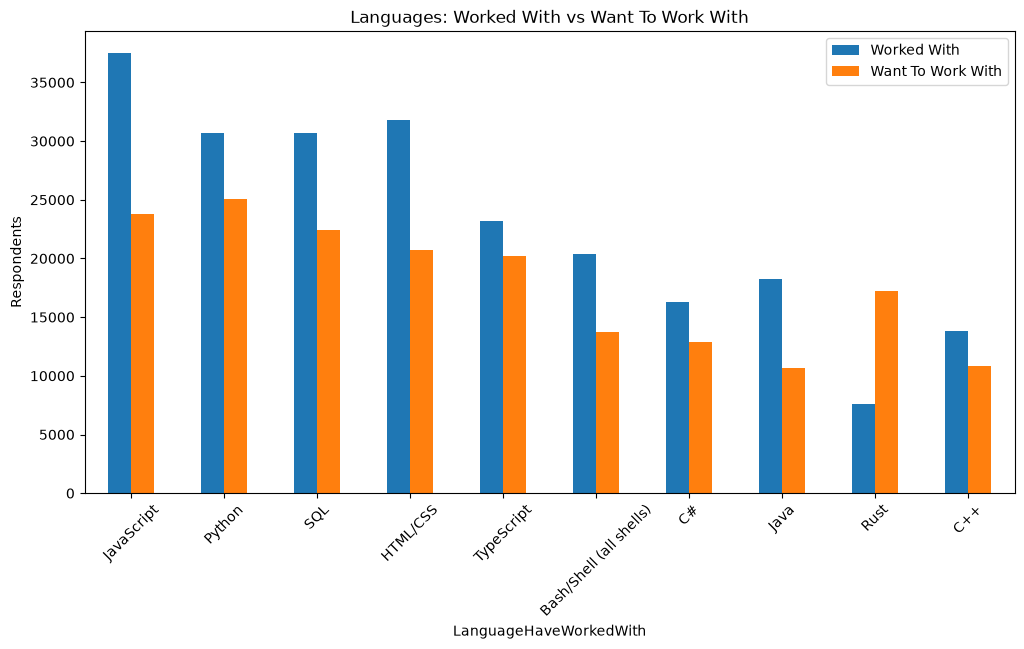

In [1]:
def lang_counts(col):
    s = df[col].dropna().str.split(';').explode().reset_index(drop=True)
    return s.value_counts()

worked = lang_counts('LanguageHaveWorkedWith')
want = lang_counts('LanguageWantToWorkWith')

top = worked.add(want, fill_value=0).nlargest(10).index
comp = pd.DataFrame({'Worked With': worked.reindex(top), 'Want To Work With': want.reindex(top)})
print(comp)

comp.plot(kind='bar', figsize=(12, 6))
plt.title('Languages: Worked With vs Want To Work With')
plt.ylabel('Respondents')
plt.xticks(rotation=45)
plt.show()

JavaScript is the most used language (37,492 respondents), while Python is the most wanted (25,047). Rust stands out: it is the only language in this top ten where more respondents want to work with it (17,232) than have worked with it (7,559), more than twice as many, which points to growing interest. For the other nine, fewer respondents want to keep using the language than currently use it; Java has the largest relative drop (18,239 vs 10,668, about 41% fewer).

## 2. Remote work by country
Share of each remote-work option among the ten countries with the most responses.

In [ ]:
top_countries = df['Country'].value_counts().head(10).index
sub = df[df['Country'].isin(top_countries)]

# Respondents who skipped RemoteWork are left out
ct = pd.crosstab(sub['Country'], sub['RemoteWork'])
ct_pct = ct.div(ct.sum(axis=1), axis=0) * 100

plt.figure(figsize=(10, 6))
sns.heatmap(ct_pct, annot=True, fmt='.0f', cmap='YlGnBu')
plt.title('Remote Work Distribution by Country (%)')
plt.show()

ct.plot(kind='bar', figsize=(12, 6))
plt.title('Remote Work by Country')
plt.ylabel('Respondents')
plt.xticks(rotation=45)
plt.show()

## 3. Job satisfaction and experience
Correlation between `JobSat` and `YearsCodePro`. Spearman is included alongside Pearson because job satisfaction is an ordinal 0 to 10 scale.

In [ ]:
df['YearsCodePro'] = df['YearsCodePro'].replace({'Less than 1 year': 0.5, 'More than 50 years': 51})
df['YearsCodePro'] = pd.to_numeric(df['YearsCodePro'], errors='coerce')

# Use only respondents who answered both questions
pair = df[['JobSat', 'YearsCodePro']].dropna()
print("Respondents with both answers:", len(pair))

pearson = pair['JobSat'].corr(pair['YearsCodePro'], method='pearson')
spearman = pair['JobSat'].corr(pair['YearsCodePro'], method='spearman')
print('Pearson :', round(pearson, 4))
print('Spearman:', round(spearman, 4))

A coefficient near 0 means little relationship and a value near 1 or -1 means a strong one. Compare the two coefficients above: if both are small, experience explains little of the difference in job satisfaction.